In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay,
    roc_curve, auc
)
from sklearn.preprocessing import label_binarize
from itertools import cycle


In [2]:
iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=19,
    stratify=y
)

print(f"Размер обучающей выборки: {X_train.shape[0]}")
print(f"Размер тестовой выборки: {X_test.shape[0]}")

Размер обучающей выборки: 105
Размер тестовой выборки: 45


In [3]:
results = []

for weights in ["uniform", "distance"]:
    for algorithm in ["brute", "kd_tree", "ball_tree", "auto"]:
        model = KNeighborsClassifier(n_neighbors=5, weights=weights, algorithm=algorithm)

        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        results.append({
            "weights": weights,
            "algorithm": algorithm,
            "accuracy": accuracy_score(y_test, y_pred)
        })

pd.DataFrame(results)

,weights,algorithm,accuracy
0,uniform,brute,1.0
1,uniform,kd_tree,1.0
2,uniform,ball_tree,1.0
3,uniform,auto,1.0
4,distance,brute,1.0
5,distance,kd_tree,1.0
6,distance,ball_tree,1.0
7,distance,auto,1.0


In [4]:
for weights in ["uniform", "distance"]:
    model = KNeighborsClassifier(n_neighbors=5, weights=weights, algorithm="auto")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print(f"weights = '{weights}'  (algorithm='auto')")
    print("\nConfusion matrix:")
    print(confusion_matrix(y_test, y_pred))
    print("\nClassification report:")
    print(classification_report(y_test, y_pred, target_names=iris.target_names))
    print()

weights = 'uniform'  (algorithm='auto')

Confusion matrix:
[[15  0  0]
 [ 0 15  0]
 [ 0  0 15]]

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      1.00      1.00        15
   virginica       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45


weights = 'distance'  (algorithm='auto')

Confusion matrix:
[[15  0  0]
 [ 0 15  0]
 [ 0  0 15]]

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      1.00      1.00        15
   virginica       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        

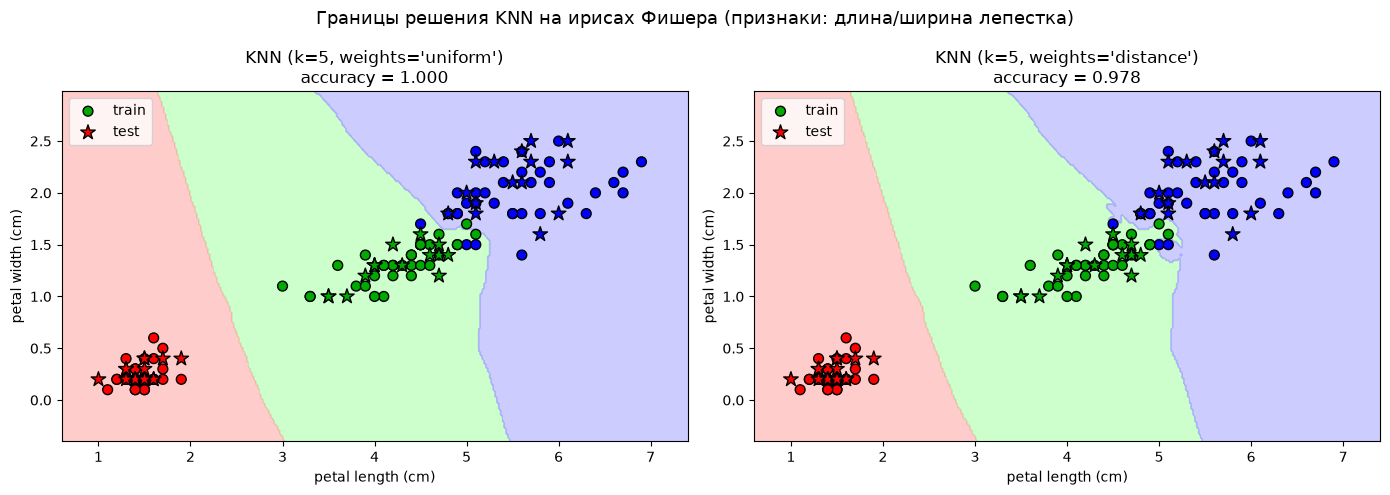

In [5]:
# Длина и ширина лепестка
feature_idx = [2, 3]
X2_train = X_train[:, feature_idx]
X2_test = X_test[:, feature_idx]

cmap_light = ListedColormap(["#FFAAAA", "#AAFFAA", "#AAAAFF"])
cmap_bold  = ListedColormap(["#FF0000", "#00AA00", "#0000FF"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, weights in zip(axes, ["uniform", "distance"]):
    clf = KNeighborsClassifier(n_neighbors=5, weights=weights)
    clf.fit(X2_train, y_train)

    x_min, x_max = X2_train[:, 0].min() - 0.5, X2_train[:, 0].max() + 0.5
    y_min, y_max = X2_train[:, 1].min() - 0.5, X2_train[:, 1].max() + 0.5

    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
    
    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.6)
    ax.scatter(X2_train[:, 0], X2_train[:, 1], c=y_train, cmap=cmap_bold, edgecolor="k", s=50, label="train")
    ax.scatter(X2_test[:, 0], X2_test[:, 1], c=y_test, cmap=cmap_bold, edgecolor="k", s=120, marker="*", label="test")

    acc = accuracy_score(y_test, clf.predict(X2_test))

    ax.set_title(f"KNN (k=5, weights='{weights}')\naccuracy = {acc:.3f}")
    ax.set_xlabel(iris.feature_names[feature_idx[0]])
    ax.set_ylabel(iris.feature_names[feature_idx[1]])
    ax.legend(loc="upper left")

plt.suptitle("Границы решения KNN на ирисах Фишера (признаки: длина/ширина лепестка)", fontsize=13)
plt.tight_layout()
plt.show()

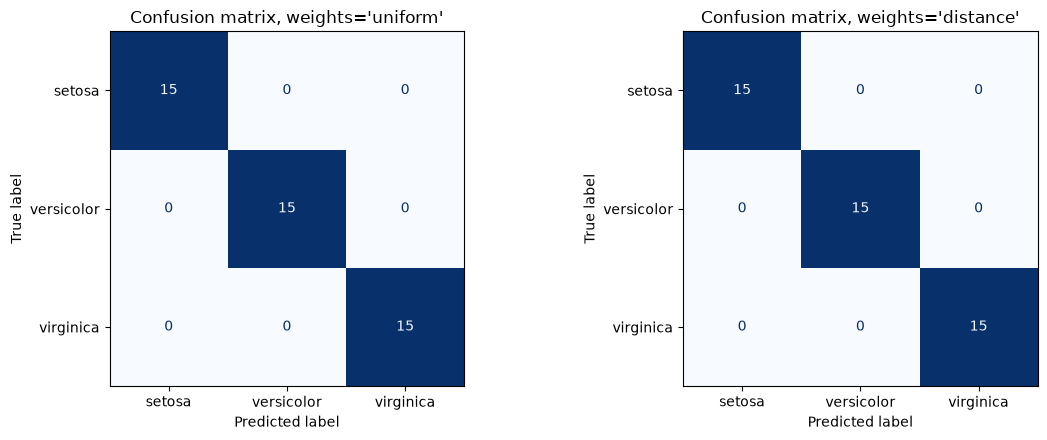

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, weights in zip(axes, ["uniform", "distance"]):
    clf = KNeighborsClassifier(n_neighbors=5, weights=weights)
    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)
    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    
    ax.set_title(f"Confusion matrix, weights='{weights}'")

plt.tight_layout()
plt.show()

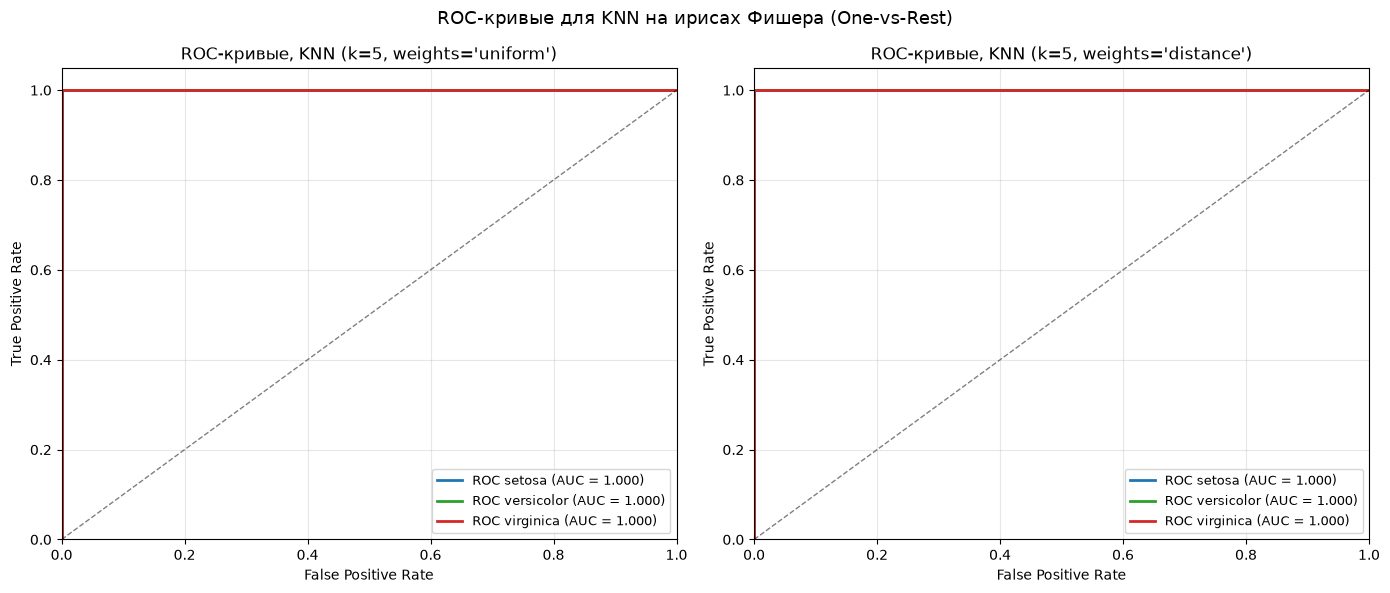

In [ ]:
classes = iris.target_names
n_classes = len(classes)

# Бинаризуем y_test: каждый класс -> отдельный бинарный столбец
y_test_bin = label_binarize(y_test, classes=range(n_classes))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, weights in zip(axes, ["uniform", "distance"]):
    clf = KNeighborsClassifier(n_neighbors=5, weights=weights)
    clf.fit(X_train, y_train)

    # predict_proba -> матрица вероятностей (n_samples, n_classes)
    y_score = clf.predict_proba(X_test)

    # По одному классу — своя ROC
    fpr, tpr, roc_auc = {}, {}, {}
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    colors = cycle(["#1f77b4", "#2ca02c", "#d62728"])
    for i, color in zip(range(n_classes), colors):
        ax.plot(fpr[i], tpr[i], color=color, lw=2,
                label=f"ROC {classes[i]} (AUC = {roc_auc[i]:.3f})")

    ax.plot([0, 1], [0, 1], "k--", lw=1, alpha=0.5)
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(f"ROC-кривые, KNN (k=5, weights='{weights}')")
    ax.legend(loc="lower right", fontsize=9)
    ax.grid(alpha=0.3)

plt.suptitle("ROC-кривые для KNN на ирисах Фишера (One-vs-Rest)", fontsize=13)
plt.tight_layout()
plt.show()